<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Metrics and Cross-Validation

##Train/Test split

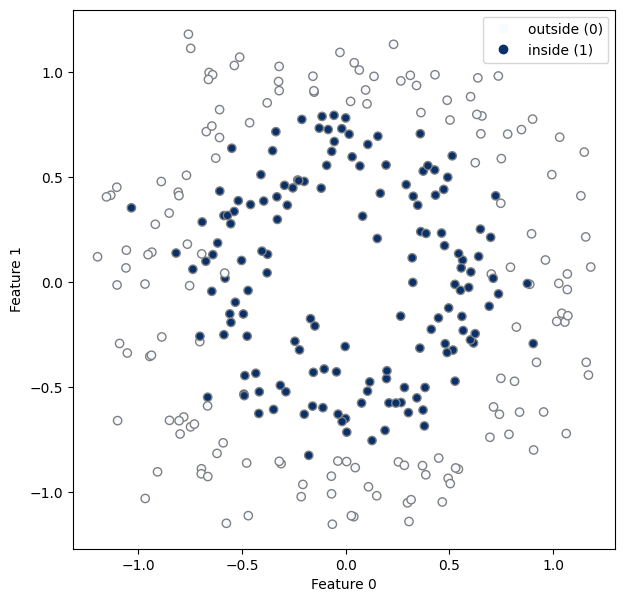

In [1]:
# COMMENTS GENERATED USING CHATGPT AS PER ABOVE TIP

# Import tools from scikit-learn for generating datasets
# and later splitting data into training/test sets.
from sklearn import datasets, model_selection

# Matplotlib is used for plotting the dataset.
import matplotlib.pyplot as plt

# NumPy is used for numerical array operations.
import numpy as np

# Number of total observations we want in the synthetic dataset.
NUM_DATAPOINTS = 300

# Generate a binary classification dataset shaped like two concentric circles.
#
# x_data contains the input features.
# Each row represents one datapoint and contains two numerical features:
#   x_data[i, 0] = Feature 0
#   x_data[i, 1] = Feature 1
#
# y_data contains the binary class labels:
#   0 = outer circle
#   1 = inner circle
#
# n_samples=300
#   Creates 300 total observations.
#
# noise=0.15
#   Adds random variation to the coordinates so the circles are not perfectly
#   separated. This makes the classification problem more realistic.
#
# factor=0.6
#   Controls the size of the inner circle relative to the outer circle.
#   A factor of 0.6 means the inner circle has roughly 60% of the radius
#   of the outer circle.
x_data, y_data = datasets.make_circles(
    n_samples=NUM_DATAPOINTS,
    noise=0.15,
    factor=0.6
)

# Create a figure and plotting area.
# figsize=(7, 7) makes the graph square, which is useful because
# the underlying data are circular.
fig, ax = plt.subplots(figsize=(7, 7))

# Plot every datapoint using Feature 0 on the x-axis
# and Feature 1 on the y-axis.
scatter = ax.scatter(
    x_data[:, 0],       # All rows from Feature 0
    x_data[:, 1],       # All rows from Feature 1
    c=y_data,           # Color each point according to its class label
    edgecolors="grey",  # Give points grey borders
    cmap="Blues",       # Use different shades of blue for the two classes
    vmin=0,             # Lowest class value is 0
    vmax=1,             # Highest class value is 1
)

# Label the horizontal and vertical axes.
ax.set_xlabel("Feature 0")
ax.set_ylabel("Feature 1")

# Create a legend showing which color corresponds to each class.
#
# The make_circles dataset assigns:
#   class 0 -> outer circle
#   class 1 -> inner circle
ax.legend(
    handles=scatter.legend_elements()[0],
    labels=["outside (0)", "inside (1)"]
)

# Display the finished plot.
plt.show()

In [2]:
x_train, x_test, y_train, y_test = model_selection.train_test_split( x_data, y_data, test_size = 0.2, random_state = 42)

##ROC-AUC

In [3]:
from sklearn import linear_model, metrics, svm

linear_clf = linear_model.LogisticRegression()
linear_clf.fit(x_train, y_train)

svm_clf = svm.SVC(gamma=2, C=1, probability=True)
svm_clf.fit(x_train, y_train)

print(linear_clf.score(x_test, y_test), svm_clf.score(x_test, y_test))

0.5166666666666667 0.9833333333333333


In [4]:
# Feel free to skip over this cell, it's just plotting code.
def plot_decision_surface(clf, xs, ys, ax, title):
    xs = np.linspace(xs[0], xs[1], 100)
    ys = np.linspace(ys[0], ys[1], 100)
    x_mesh, y_mesh = np.meshgrid(xs, ys)

    vis_x = np.stack((x_mesh, y_mesh), axis=2).reshape(-1, 2)
    vis_y = clf.predict_proba(vis_x)[:, 1].reshape(100, 100)

    contour = ax.contourf(
        x_mesh, y_mesh, vis_y, levels=np.linspace(0, 1, 33), cmap="Blues"
    )

    contour.set_clim(0, 1)
    ax.scatter(
        x_data[:, 0],
        x_data[:, 1],
        c=y_data,
        edgecolors="grey",
        cmap="Blues",
        vmin=0,
        vmax=1,
    )
    ax.set_title(title)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

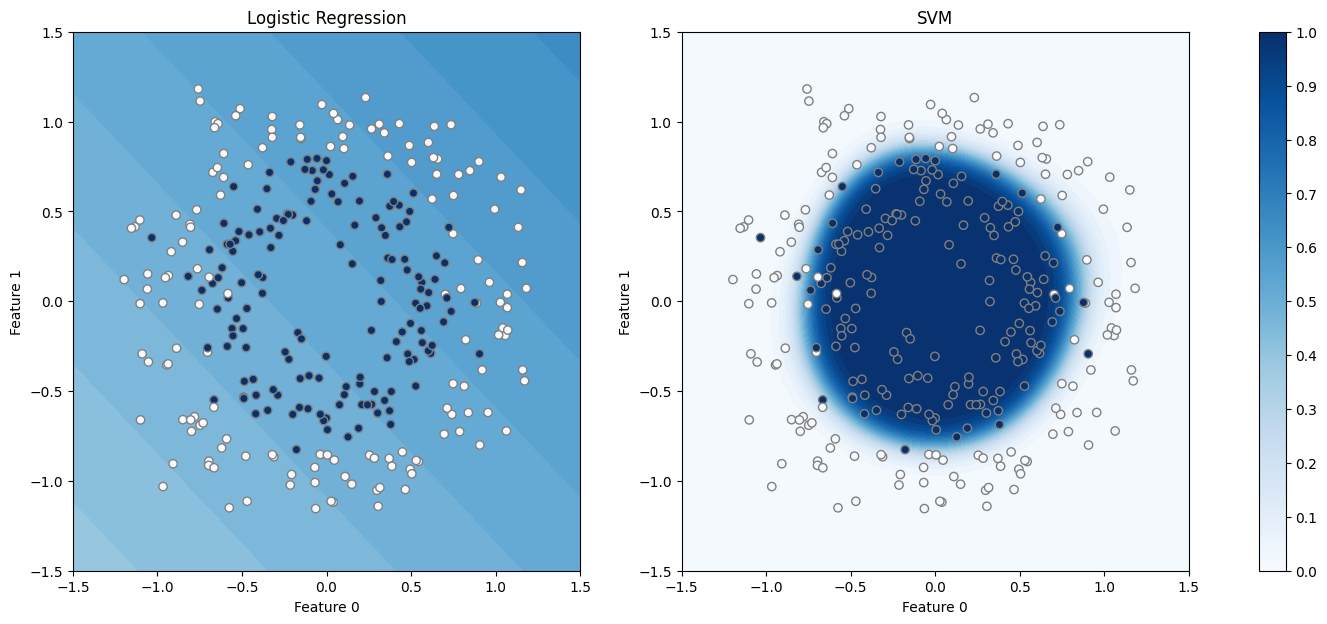

In [5]:
from matplotlib import cm

fig, ax = plt.subplots(ncols=2, figsize=(18, 7))
fig.colorbar(cm.ScalarMappable(cmap="Blues"), ticks=np.linspace(0, 1, 11), ax=ax)
plot_decision_surface(linear_clf, (-1.5, 1.5), (-1.5, 1.5), ax[0], "Logistic Regression")
plot_decision_surface(svm_clf, (-1.5, 1.5), (-1.5, 1.5), ax[1], "SVM")

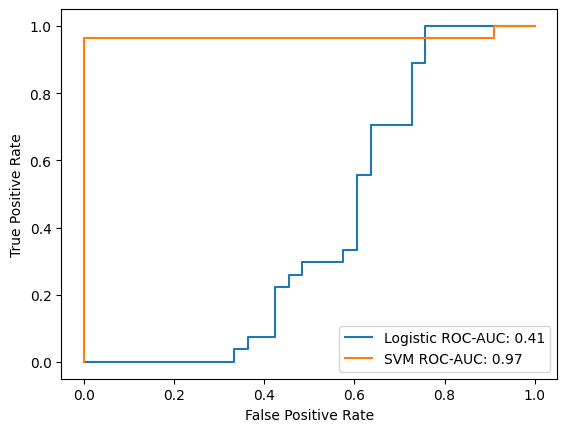

In [6]:
linear_preds = linear_clf.predict_proba(x_test)[:, 1]
svm_preds = svm_clf.predict_proba(x_test)[:, 1]

linear_curve = metrics.roc_curve(y_test, linear_preds)
svm_curve = metrics.roc_curve(y_test, svm_preds)

plt.plot(linear_curve[0], linear_curve[1], label="Logistic ROC-AUC: %.2f" % metrics.roc_auc_score(y_test, linear_preds))
plt.plot(svm_curve[0], svm_curve[1], label="SVM ROC-AUC: %.2f" % metrics.roc_auc_score(y_test, svm_preds))
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

##Train/Val/Test split

In [7]:
'''
previous code exercise, we assigned data for training and testing.
x_train, x_test, y_train, y_test = model_selection.train_test_split(x_data,y_data,test_size=0.2,random_state=42, stratify=y_data)
'''
from scipy.stats import loguniform

# now we will do the same but for validation set instead of test set
x_train_new, x_val, y_train_new, y_val = model_selection.train_test_split( x_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)
# hyperparameter values
# Random search where I am sampling C and gamma log-uniformly
n_trials = 37 # trails can be any number, the more the better
rng = np.random.default_rng(42)
c_values = loguniform(1e-2, 1e2).rvs(n_trials, random_state=rng)
gamma_values = loguniform(1e-3, 1e1).rvs(n_trials, random_state=rng)
# above sample code was suggested to me by both claude and chatgpt, which I incorporated after understanding how the functions sampled the hyperparameter values for our models to test
# but I changed the n_trails from 10 to 60
best_auc = -np.inf
best_c = None
best_gamma = None

# paired samples and n_trial total fits
for c, gamma in zip(c_values, gamma_values):
    # SVM with the hyperparameters
    model = svm.SVC(gamma=gamma, C=c, probability=True, random_state=42)
    # fitting on the training dataset only
    model.fit(x_train_new, y_train_new)
    # predicted probability for validation dataset: column 1, Feature 1 class
    val_prediction = model.predict_proba(x_val)[:, 1]
    # ROC-AUC on validation set
    val_auc = metrics.roc_auc_score(y_val, val_prediction)
    # variable switching: to find maximum element
    if val_auc > best_auc:
        best_auc = val_auc
        best_c = c
        best_gamma = gamma

print(f"Best validation ROC-AUC is {best_auc} \nbest C is {best_c} \nbest gamma is {best_gamma}")

# choosing best model given the best hyperparameters from above
model_best = svm.SVC(gamma=best_gamma, C=best_c, probability=True)
# refitting the best model on the same training dataset
model_best.fit(x_train_new, y_train_new)
# model testing
prediction_test = model_best.predict_proba(x_test)[:, 1]
auc_test = metrics.roc_auc_score(y_test, prediction_test)
print(f"Test ROC-AUC score is {auc_test}")

Best validation ROC-AUC is 0.9965217391304348 
best C is 12.468786659075652 
best gamma is 0.07995022768886643
Test ROC-AUC score is 0.9708193041526374
